# IQ Data Analysis

1. Correlation between IQ and Mri brain size.



In [168]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats 
import statsmodels.api as sm
from statsmodels.stats.diagnostic import linear_harvey_collier

Load data from ./data/iqdata.csv

In [169]:
iqdata = pd.read_csv("./data/iqdata.csv")
iqdata.head()

,Nationality,Sex,FSIQ,VIQ,PIQ,MRI_Count
0,British,Female,133,132,124,816932
1,British,Male,140,150,124,1001121
2,British,Male,139,123,150,1038437
3,Spanish,Male,133,129,128,965353
4,British,Female,137,132,134,951545


## Normality Test

First we test for normality using Shapiro Wilk's test.

H0: Data is normally distributed

H1: Data is not normally distributed

In [170]:
print(f"Assumption test: Normality [FSIQ] | {stats.shapiro(iqdata['FSIQ'])}")
print(f"Assumption test: Normality [MRI Count] | {stats.shapiro(iqdata['MRI_Count'])}")

Assumption test: Normality [FSIQ] | ShapiroResult(statistic=np.float64(0.8300553302840135), pvalue=np.float64(3.057070446944554e-05))
Assumption test: Normality [MRI Count] | ShapiroResult(statistic=np.float64(0.9712711882549291), pvalue=np.float64(0.3945132426357154))


The pvalue for FSIQ is clearly written out as: 0.00003057070.

Given a significant value of 0.05. Since, pvalue for fsiq (0.0000305) < 0.05, and pvalue for mri (0.3945) > 0.05, we reject the null hypothesis (H0). 

Therefore, The dataset is not normally distributed.

## Correlation between IQ and MRI brain size

First, we layout our null and alternate hypothesis:

H0: There is no correlation between IQ and MRI brain size

H1: There is a correlation between IQ and MRI brain size

We can plot IQ against MRI to see if dataset is linear.

<Axes: title={'center': 'Correlation of MRI Count vs. FSIQ Score'}, xlabel='MRI Count', ylabel='FSIQ'>

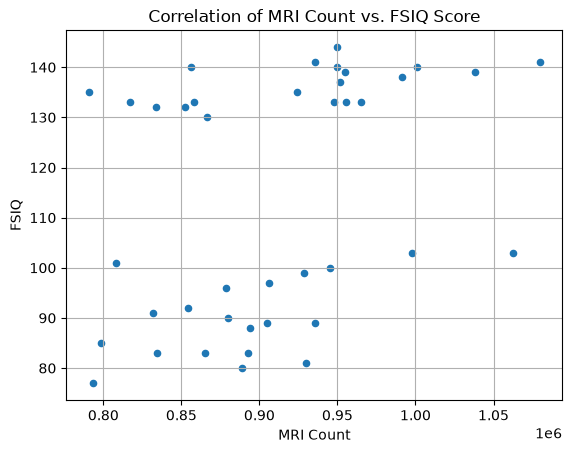

In [171]:
iq = iqdata['FSIQ']
mri = iqdata['MRI_Count']

iqdata.plot(kind="scatter", x="MRI_Count", y="FSIQ",
            title = "Correlation of MRI Count vs. FSIQ Score",
            xlabel = "MRI Count",
            ylabel = "FSIQ",
            grid=True)

By visualizing the data, we can see the dataset is not linear (can only be measured by a curve), hence we use the **Spearman Correlation**.

NB: For linear dataset, use Pearson Correlation.

In [172]:
corr, _ = stats.spearmanr(iqdata["FSIQ"], iqdata["MRI_Count"])

print(f"The Correlation value between FSIQ & MRI Count is: {corr}")

The Correlation value between FSIQ & MRI Count is: 0.47214191583899207


A correlation of 0.4721 shows a **Moderate Positive Correlation** between the FSIQ and MRI count.

## ANOVA Heights across Nations

Definition: ANOVA (Analysis of Variance) is a statistical test used to compare the means of three or more independent groups to see if at least one group mean is significantly different from the others.

See relevant data below:

In [173]:
print(iqdata[['Nationality', 'FSIQ']].head())

  Nationality  FSIQ
0     British   133
1     British   140
2     British   139
3     Spanish   133
4     British   137


Q: **Is there a difference in the IQ of people from different Nationalities in the dataset?**

### Hypothesis

H0: The IQ of people from different nationalities are the same. U1 = U2 = U3

H1: The IQ of at least one nationality is different from the others. Ui != Uj

In [174]:
# Assumption 1: Normally Distributed (alpha = 0.05)
func = stats.shapiro
norm_test = iqdata.groupby(by="Nationality")["FSIQ"].apply(func)

print(f"British: {norm_test['British']} \nSpanish: {norm_test['Spanish']} \nFrench: {norm_test['French']}\nGerman: {norm_test['German']}")

British: ShapiroResult(statistic=np.float64(0.8314599163791974), pvalue=np.float64(0.005664405419037841)) 
Spanish: ShapiroResult(statistic=np.float64(0.7556399976768197), pvalue=np.float64(0.01452611947266745)) 
French: ShapiroResult(statistic=np.float64(0.7534427604894515), pvalue=np.float64(0.013781431764330481))
German: ShapiroResult(statistic=np.float64(0.7607173040865679), pvalue=np.float64(0.007215522854784822))


With p-values, all less than 0.05, we reject the normality test null hypothesis; which means that the dataset is not normally distributed.

We can plot a histogram to show us how frequently each IQ occurs in each country.

array([<Axes: title={'center': 'British'}, ylabel='Frequency'>,
       <Axes: title={'center': 'French'}, ylabel='Frequency'>,
       <Axes: title={'center': 'German'}, ylabel='Frequency'>,
       <Axes: title={'center': 'Spanish'}, ylabel='Frequency'>],
      dtype=object)

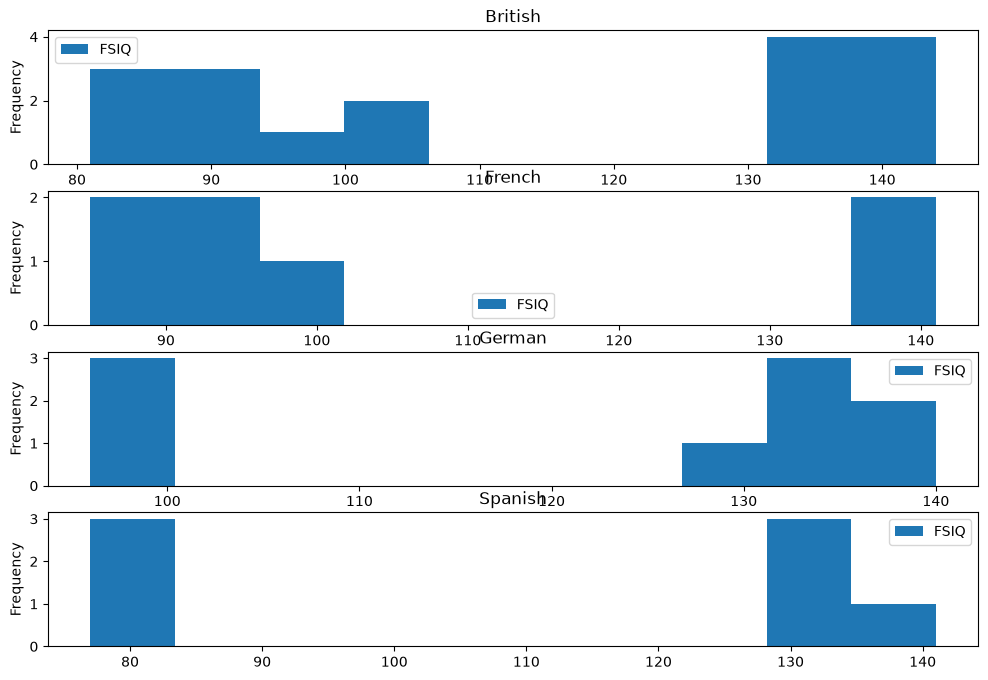

In [175]:
iqdata.plot(kind="hist", by="Nationality", column=["FSIQ"],
                figsize=(12,8))

## Levene Test

Definition: Levene's test is used to check whether two or more groups have equal population variances.

Hypotheses:

The Levene's test states the following $(\alpha = 0.05)$:

- $H_0: \sigma_1 = \sigma_2 = \sigma_3 = \sigma_4$ : The variance of each group is equal.
- $H_1: \sigma_i \neq \sigma_j$ : The variance of at least one group is different.

In [176]:
british_df = iqdata[iqdata["Nationality"] == "British"]["FSIQ"]
french_df = iqdata[iqdata["Nationality"] == "French"]["FSIQ"]
german_df = iqdata[iqdata["Nationality"] == "German"]["FSIQ"]
spanish_df = iqdata[iqdata["Nationality"] == "Spanish"]["FSIQ"]


lev_result = stats.levene(british_df, french_df, german_df, spanish_df)

print(f"The Levene's Test: {lev_result}")

The Levene's Test: LeveneResult(statistic=np.float64(0.6187587520844908), pvalue=np.float64(0.6074024775963199))


Since the Levene p-value is 0.6074 > 0.05 significant value, we fail to reject the null hypothesis. Therefore, the variance of each group is equal. Therefore, we can proceed with the standard ANOVA (instead of the Welch ANOVA).

In [177]:
stats.f_oneway(british_df,french_df,german_df,spanish_df)

F_onewayResult(statistic=np.float64(0.7319204257959432), pvalue=np.float64(0.5397663324020374))

Conducting the One-Way ANOVA test return a p-value of 0.54. Suggesting that there is insufficent evidence to reject the null hypothesis at the 5% significance level. That hypothesis being that the IQ of people from the different countries are the same.

We can produce a box-plot to provide further evidence and insight of this claim:

FSIQ    Axes(0.125,0.11;0.775x0.77)
dtype: object

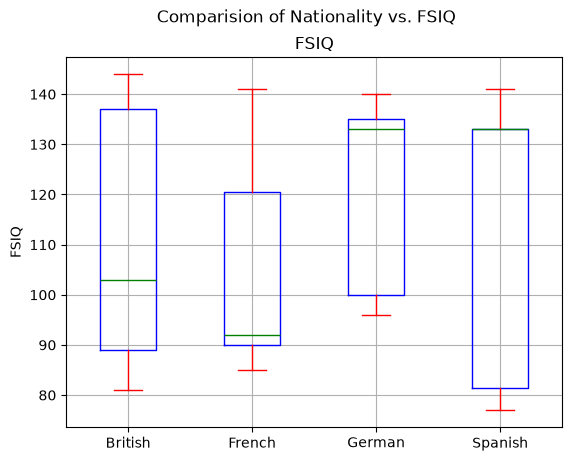

In [178]:
iqdata.plot(kind="box", by="Nationality", column=["FSIQ"],
                color=dict(boxes='b', whiskers='r', medians='g', caps='r'),
                title="Comparision of Nationality vs. FSIQ",
                ylabel="FSIQ",
                grid=True)

# Linear Regression

Q: Given the dataset of different IQ observations and their MRI size. Build a model that can predict the MRI size.

In [179]:
print(iqdata[['FSIQ', 'MRI_Count']].head())

   FSIQ  MRI_Count
0   133     816932
1   140    1001121
2   139    1038437
3   133     965353
4   137     951545


<Axes: xlabel='FSIQ', ylabel='MRI_Count'>

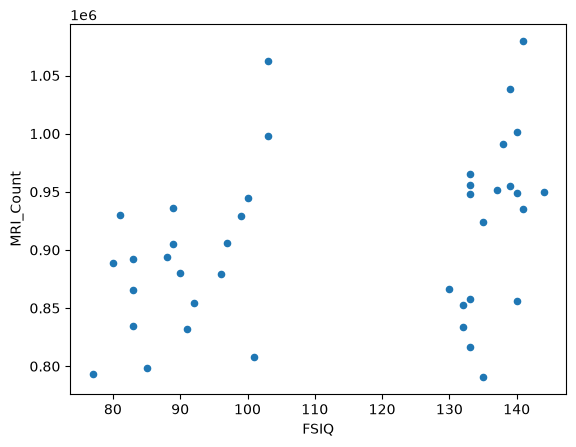

In [180]:
# Assumption 1 - Linear Relationship [SCATTER PLOT]
iqdata.plot(kind="scatter", x="FSIQ", y="MRI_Count")

Data visualization presents a data that doesnt show a clear trend. We can calculate the linear regression and then perform the "linear harvey collier test".

In [181]:
# Linear Regression - SciPy Package:
linear_res =  stats.linregress(x=iqdata["FSIQ"],y=iqdata["MRI_Count"])
print(linear_res)

LinregressResult(slope=np.float64(1073.4550953006249), intercept=np.float64(786971.519438144), rvalue=np.float64(0.35764096936905676), pvalue=np.float64(0.023468912626901667), stderr=np.float64(454.7013092794132), intercept_stderr=np.float64(52706.825389142294))


## Linearity Test

To confirm the validity of our linear regression model, we can perform a harvey collier test with Hypothesis:

H0: the regression is correctly modelled as linear.
H1: the regression is not correctly modelled as linear.

In [182]:
model = sm.OLS(iqdata["MRI_Count"], sm.add_constant(iqdata["FSIQ"])).fit()
hc = linear_harvey_collier(model)
print(f"Harvey-Collier: t = {hc.statistic:.3f}, p = {hc.pvalue:.4f}")

Harvey-Collier: t = 0.038, p = 0.9700
